In [9]:
print('Я работаю!')

Я работаю!


# Titanic

The target is a binary variable, indicating whether a person survived the sinking of the Titanic.
Other variables:
* PassengerId - unique identifier
* Pclass - ticket class; a proxy for socio-economic status (SES) (1 = Upper|2 = Middle|3 = Lower)
* Name - passenger's name
* Sex - sex (male/female)
* Age - age in years
* SibSp - number of siblings / spouses aboard the Titanic
* Parch - number of parents / children aboard the Titanic
* Ticket - ticket number
* Fare - passenger fare
* Cabin - cabin number
* Embarked - port of embarkation (C = Cherbourg|Q = Queenstown|S = Southampton)

## Import libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score

from config import config

## EDA

In [11]:
df = pd.read_csv(config.paths.path_to_dataset)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [13]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


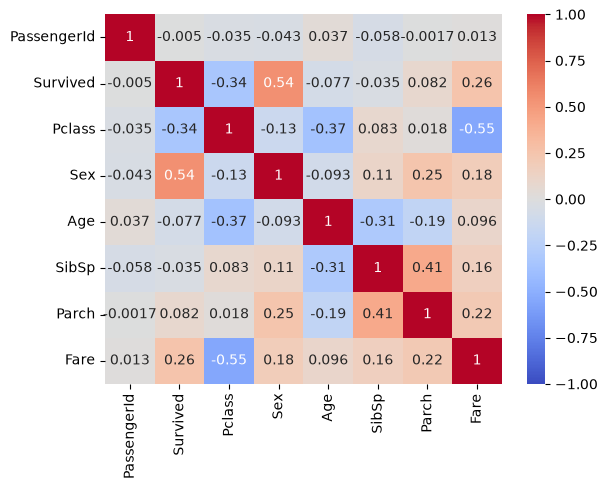

In [14]:
df_copy = df.copy()
df_copy.Sex = np.where(df_copy.Sex == 'male', 0, 1)
corr = df_copy.corr(numeric_only=True)
sns.heatmap(corr, vmin=-1, vmax=1, center=0, annot=True, cmap='coolwarm')
plt.show()

In [15]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [16]:
def get_deck(cabin):
    if type(cabin) == float:
        return 'Unknown'
    parts = cabin.split()
    if len(parts) == 1:
        return cabin[0]
    for part in parts:
        if len(part) > 1:
            return part[0]
    return 'Unknown'

df['Deck'] = df.Cabin.apply(get_deck)
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,C


In [17]:
df['Surname'] = df.Name.apply(lambda x: x[:x.find(',')])
df['Title'] = df.Name.apply(lambda x: x[x.find(',')+2:x.find('.')])
df.head(2)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Deck,Surname,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Unknown,Braund,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,C,Cumings,Mrs


In [18]:
df['IsGroupTicket'] = (df.groupby('Ticket')['PassengerId'].transform('count') > 1).astype(int)
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Deck,Surname,Title,IsGroupTicket
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Unknown,Braund,Mr,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,C,Cumings,Mrs,0


In [19]:
(df.nunique() == 2).sum()

np.int64(3)

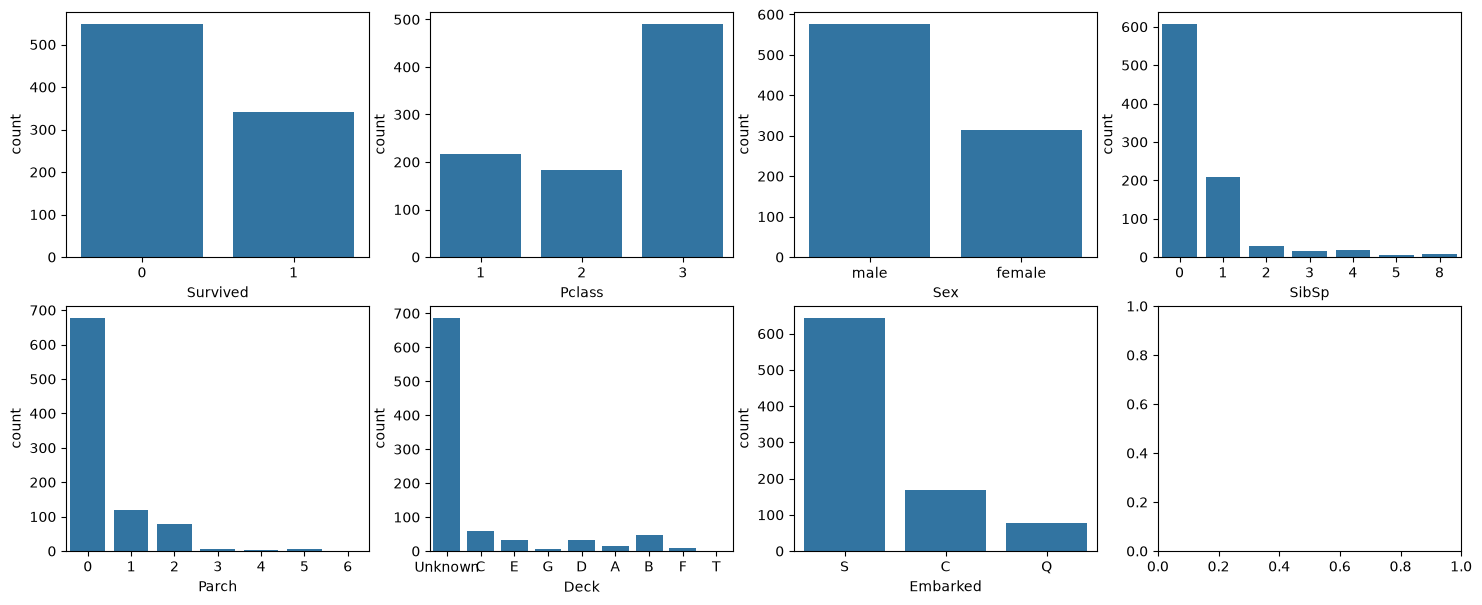

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
sns.countplot(df, ax=axes[0, 0],  x='Survived')
sns.countplot(df, ax=axes[0, 1],  x='Pclass')
sns.countplot(df, ax=axes[0, 2],  x='Sex')
sns.countplot(df, ax=axes[0, 3],  x='SibSp')
sns.countplot(df, ax=axes[1, 0],  x='Parch')
sns.countplot(df, ax=axes[1, 1],  x='Deck')
sns.countplot(df, ax=axes[1, 2],  x='Embarked')

plt.show()

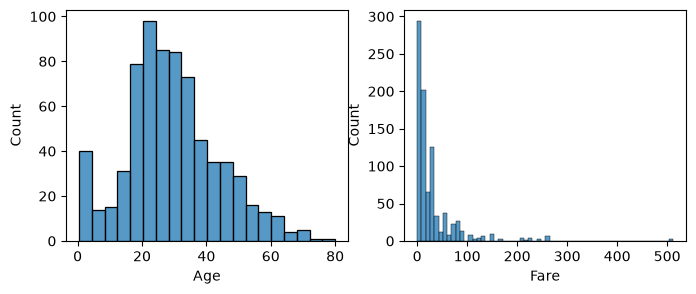

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sns.histplot(df, ax=axes[0], x='Age')
sns.histplot(df, ax=axes[1], x='Fare')
plt.show()

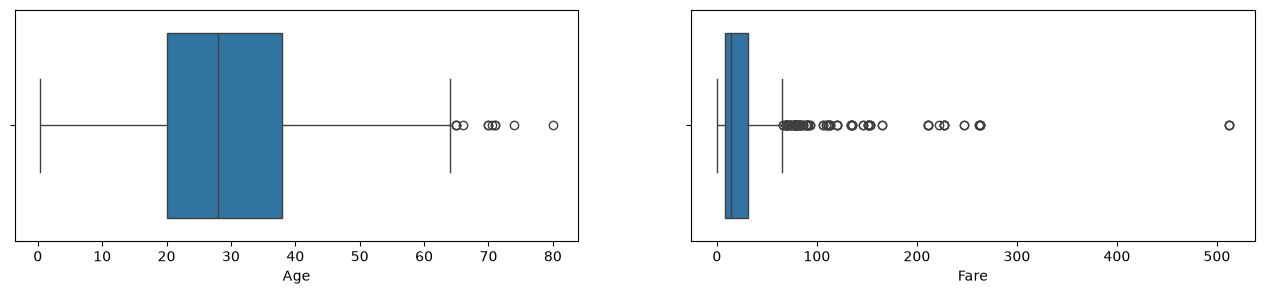

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))
sns.boxplot(df, ax=axes[0], x='Age')
sns.boxplot(df, ax=axes[1], x='Fare')
plt.show()